# 1 · Riemannian metrics and geodesics

**The idea.**  Whether a motion is "short" depends on what it costs.  Crossing a muddy field is
slower than walking around it; swinging a stretched arm costs more energy than swinging a folded
one.  A **Riemannian metric** $G(q)$ writes such costs down: at every point $q$ of a space it
is a symmetric positive-definite matrix that says how expensive it is to move in each direction.
The cheapest motions under $G$ are the **geodesics**.

The space can be anything with coordinates — the plane a mobile robot moves in, the joint angles
of an arm, the state of a cart-pole.  We start with the plane to build intuition, then move to the
configuration space of a robot arm, the running example of the tutorial.

In this notebook:
1. a metric on the plane, and the length of a path;
2. a robot arm and its configuration space;
3. metrics for the arm (kinetic energy, Jacobi, pull-back);
4. lengths of joint-space paths;
5. geodesics as "straightest" curves, obtained by shooting.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80

from geodf import metrics, plotting as P
from geodf.robots import PlanarArm

torch.set_default_dtype(torch.float64)
pi = np.pi

## 1. A metric on the plane

A metric assigns to each point $q$ a matrix $G(q)$, and measures velocities with

$$\|\dot q\|_{G(q)}=\sqrt{\dot q^\top G(q)\,\dot q},$$

so the length (cost) of a path $\gamma(s)$ is

$$L(\gamma)=\int\|\dot\gamma(s)\|_{G(\gamma(s))}\,ds .$$

With $G=I$ this is the usual Euclidean length.  As a first example take a plane with a "muddy"
disc in the middle where moving costs up to four times more:
$G(q)=c(q)^2I$ with $c(q)=1+3\,e^{-\|q\|^2/0.8}$.

A good way to *see* a metric is to draw, at many points, the velocities of unit cost
$\{\dot q:\dot q^\top G\dot q=1\}$: circles here (all directions cost the same), small where
moving is expensive.

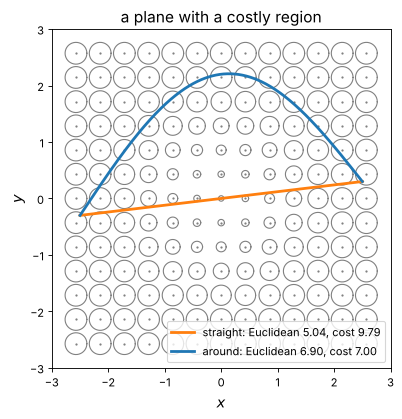

In [2]:
def G_mud(q):
    c = 1 + 3 * torch.exp(-(q ** 2).sum(-1) / 0.8)
    return (c ** 2)[..., None, None] * torch.eye(2, dtype=q.dtype)


qa, qb = np.array([-2.5, -0.3]), np.array([2.5, 0.3])
straight = np.linspace(qa, qb, 300)
t = np.linspace(0, 1, 300)[:, None]
around = (1 - t) * qa + t * qb + np.sin(pi * t) * np.array([0.0, 2.2])   # bend around the mud
bounds = ((-3, 3), (-3, 3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
P.metric_ellipses(ax, G_mud, bounds=bounds, density=13)
for name, path, c in [("straight", straight, "tab:orange"), ("around", around, "tab:blue")]:
    L = metrics.metric_length(G_mud, torch.as_tensor(path)).item()
    E = np.sum(np.linalg.norm(np.diff(path, axis=0), axis=1))
    ax.plot(*path.T, color=c, lw=2.5, label=f"{name}: Euclidean {E:.2f}, cost {L:.2f}")
ax.legend(loc="lower right")
P.setup_ax(ax, bounds=bounds, labels=("$x$", "$y$"), title="a plane with a costly region")
plt.show()

Going around is longer on the map but cheaper under the metric.  The cheapest path of all is the
geodesic; notebook 2 computes it.  Metrics can also be **anisotropic** — cheap in some directions
and expensive in others (ellipses instead of circles) — which is what happens for robots.

## 2. A robot arm and its configuration space

Two links of length $l_1=l_2=2$ with point masses $m_1=m_2=1$ at the elbow and at the
end-effector.  A configuration is a point $q=(q_1,q_2)\in[-\pi,\pi]^2$ of the **configuration
space** ($q_2$ is measured relative to the first link): every motion of the arm is a curve in
this square, and a metric on the square says what such a motion costs.

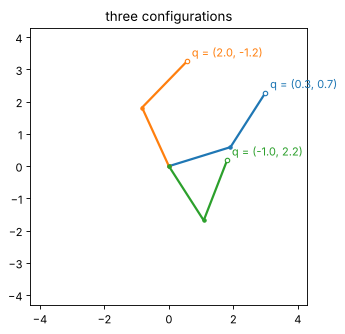

In [3]:
arm = PlanarArm()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for q, c in [((0.3, 0.7), "tab:blue"), ((2.0, -1.2), "tab:orange"), ((-1.0, 2.2), "tab:green")]:
    P.draw_arm(ax, arm, np.array(q), color=c)
    ax.text(*arm.fk(torch.tensor(q))[...].numpy() + 0.15, f"q = {q}", color=c)
ax.set_xlim(-4.3, 4.3); ax.set_ylim(-4.3, 4.3); ax.set_aspect("equal"); ax.set_title("three configurations")
plt.show()

The kinetic energy of the arm is $T=\tfrac12\dot q^\top M(q)\dot q$, with the
configuration-dependent **inertia matrix**

$$M(q)=\begin{pmatrix}(m_1+m_2)l_1^2+m_2l_2^2+2m_2l_1l_2\cos q_2 & m_2l_2^2+m_2l_1l_2\cos q_2\\ m_2l_2^2+m_2l_1l_2\cos q_2 & m_2l_2^2\end{pmatrix}.$$

It depends only on the elbow angle $q_2$: a stretched arm ($q_2=0$) is much "heavier" to
rotate around the shoulder than a folded one ($q_2=\pm\pi$).

In [4]:
for q in [(0.0, 0.0), (0.0, pi / 2), (0.0, pi)]:
    M = arm.inertia(torch.tensor([q]))[0]
    print(f"q = ({q[0]:.2f}, {q[1]:.2f})   M(q) =\n{M.numpy().round(2)}\n")

q = (0.00, 0.00)   M(q) =
[[20.  8.]
 [ 8.  4.]]

q = (0.00, 1.57)   M(q) =
[[12.  4.]
 [ 4.  4.]]

q = (0.00, 3.14)   M(q) =
[[4. 0.]
 [0. 4.]]



## 3. Metrics for the arm

Choosing $G=M$ (the **kinetic-energy metric**) makes $\tfrac12\|\dot q\|_G^2$ exactly the
kinetic energy.  Drawn as before, the unit-cost sets are now ellipses: long axes are cheap
directions, short axes expensive ones.

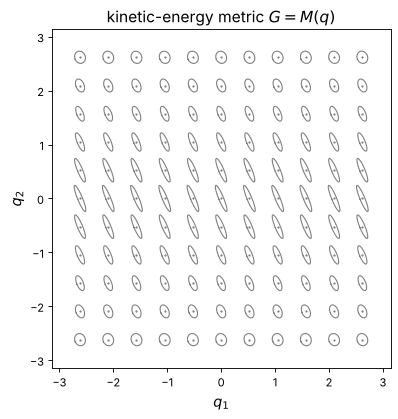

In [5]:
G_ke = metrics.kinetic_energy(arm)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
P.metric_ellipses(ax, G_ke, density=11)
P.setup_ax(ax, title="kinetic-energy metric $G=M(q)$")
plt.show()

Near $q_2=0$ (stretched arm) the ellipses are thin and tilted: rotating the whole arm about
the shoulder is expensive (both masses move, the outer one on a long lever arm), while
turning shoulder and elbow in opposite directions, roughly $\dot q\propto(1,-2.4)$, is cheap:
then the end-effector mass barely moves and only the elbow mass does.  Near $q_2=\pm\pi$
(folded arm) $M=4I$: the ellipses are round and larger, motion is cheap in every direction.

The same framework accepts other metrics, each encoding a different notion of "cost":

* **Jacobi metric** $G=2\,(H-P(q))\,M(q)$ for a robot with total energy $H$ and potential
  energy $P$ (gravity).  By Maupertuis' principle, the paths of the *free* (unactuated) robot
  with energy $H$ are exactly its geodesics.
* **Pull-back metric** $G=J(q)^\top J(q)$, with $J$ the Jacobian of the forward kinematics.
  It measures how far the *end-effector* moves, so its geodesics move the end-effector along
  short task-space paths.

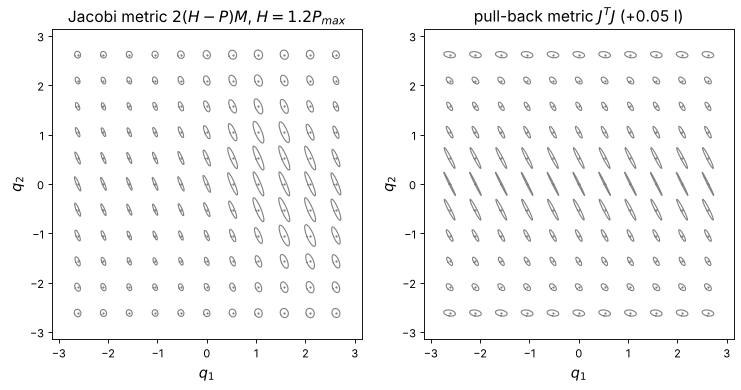

In [6]:
H = 1.2 * arm.P_max
G_jac = metrics.jacobi(arm, H)
G_pb = metrics.pullback(arm, reg=0.05)
fig, axs = plt.subplots(1, 2, figsize=(11, 5.3))
P.metric_ellipses(axs[0], G_jac, density=11)
P.setup_ax(axs[0], title="Jacobi metric $2(H-P)M$, $H=1.2P_{max}$")
P.metric_ellipses(axs[1], G_pb, density=11)
P.setup_ax(axs[1], title="pull-back metric $J^TJ$ (+0.05 I)")
plt.show()

In the Jacobi metric the ellipses are largest around $q_1\approx\pi/2$: there the arm points
up, the potential energy is high and the remaining kinetic energy $H-P$ is small, so moving
there is "cheap" in the sense of the action.  In the pull-back metric the ellipses collapse to
lines near $q_2=0$ and $q_2=\pm\pi$ — at these singular configurations some joint motions do
not move the end-effector at all.

## 4. Length of a joint-space path

`metrics.metric_length` evaluates the length of a discretised path.  Let us compare two paths that
connect the same configurations: the straight line in joint space, and a detour that first
folds the elbow further.

straight line                 Euclidean length  4.00   kinetic-energy length 13.60
detour via a folded elbow     Euclidean length  5.48   kinetic-energy length 12.35


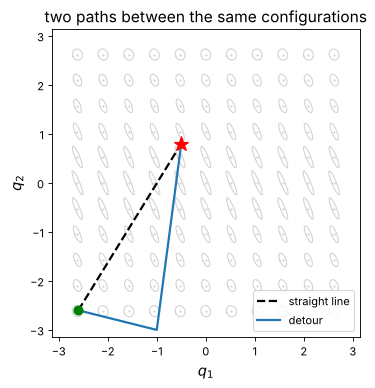

In [7]:
qa, qb = np.array([-2.6, -2.6]), np.array([-0.5, 0.8])
straight = np.linspace(qa, qb, 200)
via = np.array([-1.0, -3.0])                                  # fold the elbow first
detour = np.vstack([np.linspace(qa, via, 100), np.linspace(via, qb, 100)])

for name, path in [("straight line", straight), ("detour via a folded elbow", detour)]:
    L_ke = metrics.metric_length(G_ke, torch.as_tensor(path)).item()
    L_eu = np.sum(np.linalg.norm(np.diff(path, axis=0), axis=1))
    print(f"{name:28s}  Euclidean length {L_eu:5.2f}   kinetic-energy length {L_ke:5.2f}")

fig, ax = plt.subplots(figsize=(5, 5))
P.metric_ellipses(ax, G_ke, density=11, color="lightgray")
ax.plot(*straight.T, "k--", lw=2, label="straight line")
ax.plot(*detour.T, "tab:blue", lw=2, label="detour")
ax.plot(*qa, "go", ms=8); ax.plot(*qb, "r*", ms=14)
ax.legend(loc="lower right")
P.setup_ax(ax, title="two paths between the same configurations")
plt.show()

The detour is longer in joint space but **shorter** under the kinetic-energy metric: it passes
through configurations where moving is cheap.  The *shortest* path under $G$ is the geodesic.
Finding it between two given configurations is a boundary-value problem, which is hard in
general — the next notebooks solve it for all pairs at once with a distance field.

## 5. Geodesics as "straightest" curves

Locally, geodesics satisfy the geodesic equation
$\ddot q^k=-\Gamma^k_{ij}(q)\,\dot q^i\dot q^j$, where the Christoffel symbols $\Gamma$ are
built from derivatives of $G$ (`metrics.christoffel` computes them with autograd).  For the
kinetic-energy metric this is exactly the motion of the arm *without gravity and without
torques*: the "straightest" motion the robot can do on its own.

Integrating this equation from one configuration in many directions ("shooting") shows how
the metric bends geodesics.

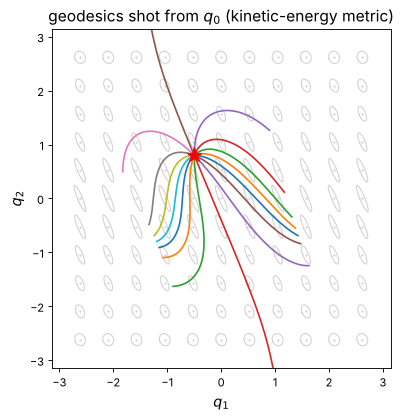

In [8]:
def geodesic_shoot(G, q0, v0, length=6.0, h=0.02):
    """Integrate the geodesic equation with RK4 at unit G-speed."""
    def unit(q, v):
        return v / torch.sqrt(torch.einsum("ni,nij,nj->n", v, G(q), v))[:, None]

    def rhs(q, v):
        return v, -torch.einsum("nkij,ni,nj->nk", metrics.christoffel(G, q), v, v)

    q, v = torch.as_tensor(q0)[None], unit(torch.as_tensor(q0)[None], torch.as_tensor(v0)[None])
    path = [q[0].numpy()]
    for _ in range(int(length / h)):
        k1 = rhs(q, v); k2 = rhs(q + h / 2 * k1[0], v + h / 2 * k1[1])
        k3 = rhs(q + h / 2 * k2[0], v + h / 2 * k2[1]); k4 = rhs(q + h * k3[0], v + h * k3[1])
        q = q + h / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
        v = unit(q, v + h / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1]))
        path.append(q[0].numpy())
        if np.abs(path[-1]).max() > pi:
            break
    return np.array(path)


q0 = np.array([-0.5, 0.8])
fig, ax = plt.subplots(figsize=(5.5, 5.5))
P.metric_ellipses(ax, G_ke, density=11, color="lightgray")
for ang in np.linspace(0, 2 * pi, 16, endpoint=False):
    g = geodesic_shoot(G_ke, q0, np.array([np.cos(ang), np.sin(ang)]))
    ax.plot(*g.T, lw=1.5)
ax.plot(*q0, "r*", ms=14)
P.setup_ax(ax, title="geodesics shot from $q_0$ (kinetic-energy metric)")
plt.show()

With a Euclidean metric these would be 16 straight rays.  Here they bend towards the
cheap regions and spread unevenly.  Shooting is easy, but to connect *two given*
configurations we would have to search for the right initial direction — and the search
can end in local minima.  The distance-field approach of the next notebook avoids this.